# 02 — Design-space search

Can the constraints alone lead back to S40? `stackpieces.sweep.search` enumerates shoulder and nesting pieces
(cone angle, shoulder width, tip size, band height), builds each, drops the ones that fail a hard check, and
ranks the rest by **smooth capture**: the largest offset up to which a gentle release seats at every offset
(2D model, mid friction). Then the finalists are rerun with printed layers, which is the number that matters
(DD-STACK SP-11).

In [1]:
# Setup: works from this folder whether or not the package was pip-installed
import sys, os, json
HERE = os.path.abspath("")
ROOT = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
import stackpieces
print("stackpieces", stackpieces.__version__, "| folder", os.path.relpath(ROOT))
CONSTRAINTS = os.path.join(ROOT, "constraints", "checkers_rot3u.json")
REFERENCE = os.path.join(ROOT, "results", "reference", "results.json")
c = json.load(open(CONSTRAINTS))
QUICK = True   # True: a few minutes, coarse. False: the full reference run (tens of minutes).

stackpieces 0.1.0 | folder ..


In [2]:
import pandas as pd, time
from stackpieces.sweep import search, DEFAULT_GRID, QUICK_GRID
t = time.time()
recs = search(c, DEFAULT_GRID)     # about 25 s; the full grid is cheap
print(f"{len(recs)} candidates in {time.time() - t:.0f} s; {sum(r['passes'] for r in recs)} pass the hard checks")
from collections import Counter
print("rejected by:", Counter(r["reasons"][0].split(":")[0] for r in recs if not r["passes"]))

185 candidates in 26 s; 23 pass the hard checks
rejected by: Counter({'geometry': 67, 'overhang': 48, 'rim': 33, 'height': 7, 'roof': 7})


In [3]:
top = [r for r in recs if r["passes"]][:15]
pd.DataFrame([dict(name=r["name"], H=r["H"], band=r["band_h"], geometric_capture=r["capture_geom"],
                   smooth_capture=r["capture_smooth"]) for r in top])

,name,H,band,geometric_capture,smooth_capture
0,S35-b12.5-s3-t4,23.21,12.5,8.0,7.5
1,S40-b12-s3-t1.6,22.37,12.0,9.2,7.0
2,S40-b12.5-s3-t1.6,22.87,12.5,9.2,7.0
3,S40-b12.5-s3-t4,21.44,12.5,8.0,6.0
4,S45-b15-s3-t1.6,23.70,15.0,9.2,6.0
5,S40-b15-s3-t4,23.94,15.0,8.0,6.0
6,S45-b12-s3-t1.6,20.70,12.0,9.2,5.5
7,S40-b12-s3-t4,20.94,12.0,8.0,5.5
8,S45-b12.5-s3-t1.6,21.20,12.5,9.2,5.5
9,S45-b12-s2-t1.6,21.70,12.0,10.2,5.5


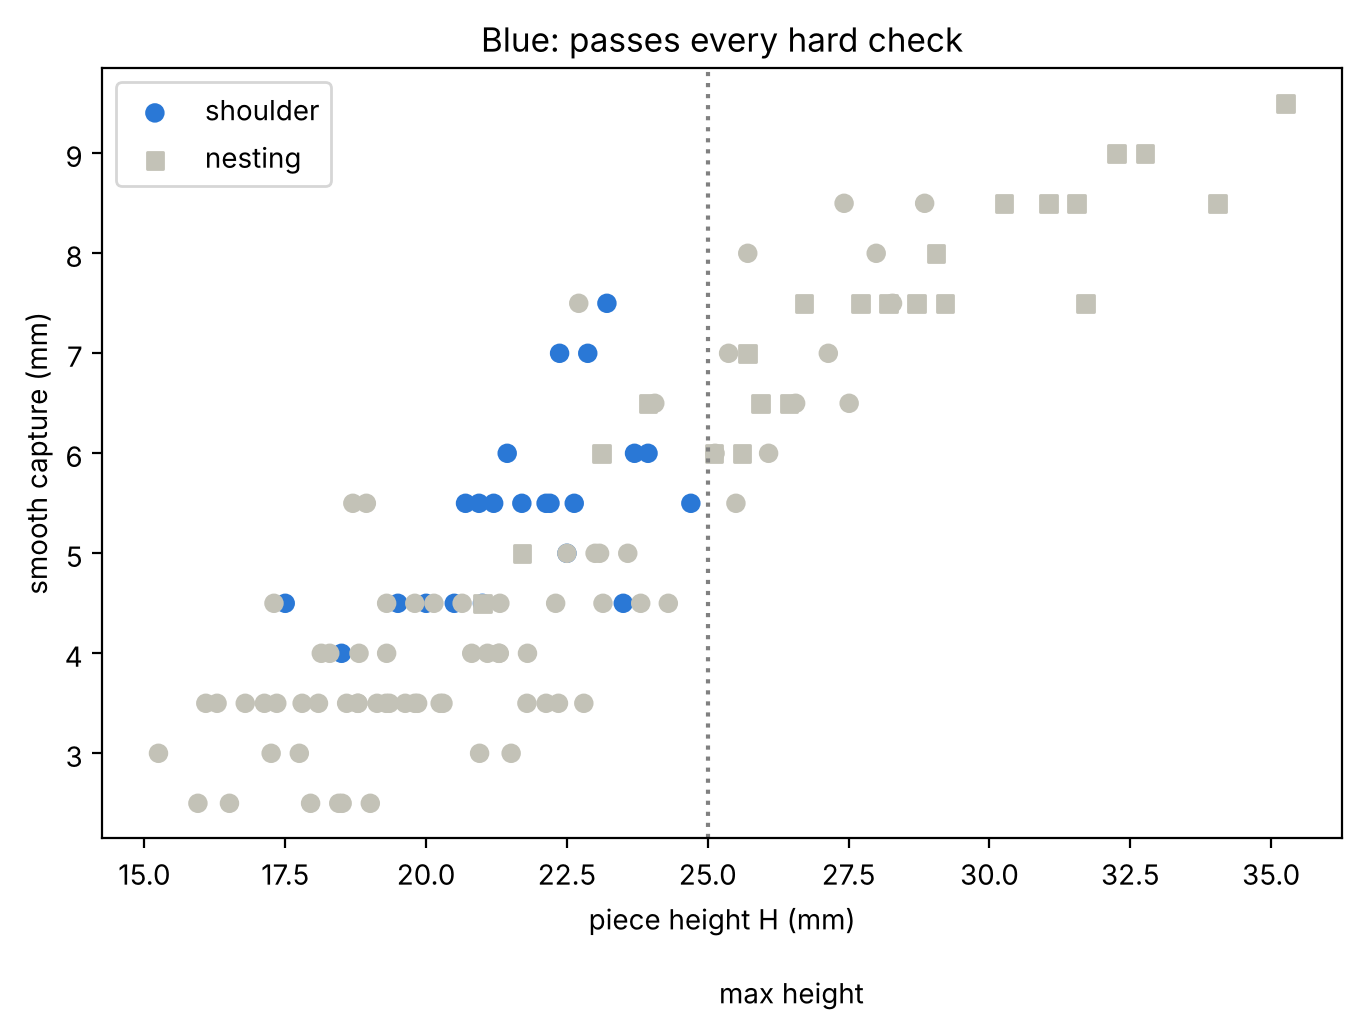

In [4]:
ok = [r for r in recs if r.get("buildable") and r["params"]["family"] != "cylinder"]
fig, ax = plt.subplots(figsize=(8, 5))
for fam, mk in (("shoulder", "o"), ("nesting", "s")):
    pts = [r for r in ok if r["params"]["family"] == fam]
    ax.scatter([r["H"] for r in pts], [r["capture_smooth"] for r in pts], marker=mk, label=fam,
               c=["#2a78d6" if r["passes"] else "#c3c2b7" for r in pts])
ax.axvline(c["goal"]["max_height_mm"], ls=":", c="0.5"); ax.text(c["goal"]["max_height_mm"] + 0.2, 0.5, "max height")
ax.set_xlabel("piece height H (mm)"); ax.set_ylabel("smooth capture (mm)"); ax.legend(); ax.set_title("Blue: passes every hard check")
plt.show()

## Printed-layer confirmation of the finalists

The smooth ranking is only a screen: printed ridges cut every design's range, by different amounts. Quick mode
uses 6 releases per offset (±40 points); the reference used 20.

In [5]:
from stackpieces.geometry import make_piece
from stackpieces.montecarlo import stacking_curve, crossing, reliable_offset
k_final, n = (3, 6) if QUICK else (6, 20)
finals = [r for r in recs if r["passes"] and r["params"]["family"] != "cylinder"][:k_final]
s40 = next(r for r in recs if r["name"] == "S40-b12-s2-t4")
if s40 not in finals: finals.append(s40)
offs = [x * 0.5 for x in range(21)]
for r in finals:
    cv = stacking_curve(make_piece(r["params"]), c, "layered", n=n, offsets=offs)
    r["printed_e50"] = crossing(cv); r["printed_reliable"] = reliable_offset(cv, c["goal"]["seat_rate_required"])
    print(f"{r['name']:22s} H {r['H']:5.1f}  smooth {r['capture_smooth']:4.1f}  printed 50 % at {r['printed_e50']:.2f} mm")

S35-b12.5-s3-t4        H  23.2  smooth  7.5  printed 50 % at 5.00 mm


S40-b12-s3-t1.6        H  22.4  smooth  7.0  printed 50 % at 5.00 mm


S40-b12.5-s3-t1.6      H  22.9  smooth  7.0  printed 50 % at 3.83 mm


S40-b12-s2-t4          H  22.1  smooth  5.5  printed 50 % at 3.00 mm


## What the reference run found

In the reference run (results/reference), S40 as specified (2 mm shoulder) is not the best shoulder piece: the
same cone angle with a **3 mm shoulder** (S40-b12-s3-t4, 20.9 mm tall) or a 35° cone with a 3 mm shoulder
(S35-b12.5-s3-t4, 23.2 mm) seat further off center when printed. See docs/method.md, "Search result".

In [6]:
import json, os
if os.path.exists(REFERENCE):
    ref = json.load(open(REFERENCE))
    fin = [r for r in ref["search"] if r.get("printed")]
    print("reference finalists (printed 50 % point, mm):")
    for r in fin: print(f"  {r['name']:22s} H {r['H']:5.1f}  printed 50 % {r['printed']['e50']:.2f}  reliable {r['printed']['reliable']}")
    print("search best:", ref["best"])

reference finalists (printed 50 % point, mm):
  S35-b12.5-s3-t4        H  23.2  printed 50 % 5.11  reliable 3.5
  S40-b12-s3-t1.6        H  22.4  printed 50 % 3.93  reliable 2.0
  S40-b12.5-s3-t1.6      H  22.9  printed 50 % 3.86  reliable 2.5
  S40-b12.5-s3-t4        H  21.4  printed 50 % 4.88  reliable 3.5
  S45-b15-s3-t1.6        H  23.7  printed 50 % 2.75  reliable 1.5
  S40-b15-s3-t4          H  23.9  printed 50 % 3.94  reliable 3.5
search best: S35-b12.5-s3-t4
